# 04. Смешанная модель в sommer


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Та же H-модель записывается формулой `mmes`: случайный эффект изделия с `Gu = H` и случайный завод.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv`, `data/markers.csv` |
| **Цель** | Повторить ssGBLUP без ручной сборки Z |
| **Результат** | Оценки `bu`, PEV и reliability |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)
library(sommer)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



Loading required package: MASS


... (3 outputs left out)


Attaching package: ‘crayon’



The following object is masked from ‘package:ggplot2’:

    %+%




Attaching package: ‘sommer’



The following objects are masked from ‘package:rrBLUP’:

    A.mat, GWAS



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv") %>%
  dplyr::select(item_id, line_age, batch_mass, batch_no, batch_size, event_season, event_year, factory, trait)
markers <- read.csv("data/markers.csv", colClasses = c(item_id = "character", panel = "character"))
lineage <- read.csv("data/lineage.csv")
measurements <- z_score_filter(measurements, 3) %>% drop_na()
prep <- prepare_ids(lineage, measurements, markers)
lineage_bl <- order_lineage(prep$lineage, unique(c(prep$measurements$item_id, prep$markers$item_id)))
meas_bl <- prep$measurements %>%
  mutate(
    item_id = factor(item_id),
    event_season = factor(event_season),
    event_year = factor(event_year),
    factory = factor(factory)
  )
mark_bl <- prep$markers


# 1. Матрица H


In [5]:
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
if (nrow(A) == nrow(lineage_bl)) {
  rownames(A) <- as.character(lineage_bl$item_id)
  colnames(A) <- as.character(lineage_bl$item_id)
}
M <- t(sapply(mark_bl$panel, function(x) as.numeric(strsplit(x, "")[[1]])))
rownames(M) <- as.character(mark_bl$item_id)
G <- A.mat(as.matrix(M))
common <- intersect(rownames(G), rownames(A))
H <- A
H[common, common] <- A[common, common] + (G[common, common] - A[common, common])
keep <- intersect(as.character(meas_bl$item_id), rownames(H))
H <- H[keep, keep]
full_data <- meas_bl %>%
  filter(as.character(item_id) %in% keep) %>%
  mutate(item_id = factor(as.character(item_id), levels = rownames(H)))
dim(H); nrow(full_data)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 0.0001833333  minutes 


[1] 199 199


[1] 199


# 2. mmes


In [6]:
model <- mmes(
  trait ~ line_age + batch_mass + batch_no + batch_size + event_season + event_year,
  random = ~ vsm(ism(item_id), Gu = H) + factory,
  rcov = ~ units,
  data = full_data,
  verbose = FALSE
)
bu <- model$bu[, 1]
names(bu) <- rownames(model$bu)
solutions <- data.frame(
  item_id = names(bu),
  estimate = as.numeric(bu),
  stringsAsFactors = FALSE
)
pev <- tryCatch(as.numeric(model$uPevList[[1]][, 1]), error = function(e) rep(NA_real_, length(bu)))
sigma2_u <- tryCatch(as.numeric(model$theta[[1]][1, 1]), error = function(e) var(bu, na.rm = TRUE))
if (length(pev) == nrow(solutions)) {
  solutions$reliability <- 1 - pev / sigma2_u
} else {
  solutions$reliability <- NA_real_
}
head(solutions, 8)


Version out of date. Please update sommer to the newest version using:
install.packages('sommer') in a new session
 Use the 'dateWarning' argument to disable the warning message.


     item_id     estimate reliability
1  Intercept  0.128724197          NA
2   line_age  0.301681238          NA
3 batch_mass  0.407627134          NA
4   batch_no  0.002515746          NA
5 batch_size  0.095264624          NA
6     spring -0.306582743          NA
7     summer -0.187441952          NA
8     winter -0.092900313          NA


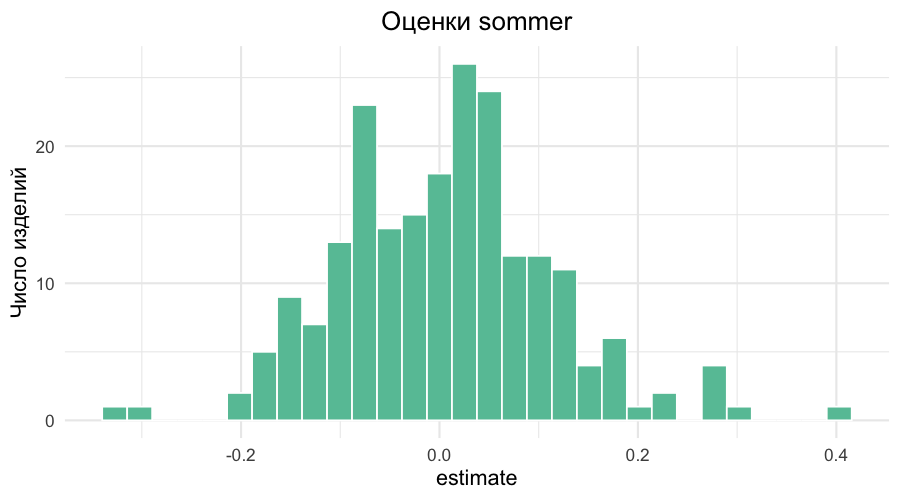

In [7]:
ggplot(solutions, aes(x = estimate)) +
  geom_histogram(bins = 30, fill = "#66C2A5", color = "white") +
  labs(title = "Оценки sommer", x = "estimate", y = "Число изделий") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

`mmes` снимает ручную склейку Z и K. Формула читается как спецификация модели: фиксированные эффекты партии, случайное изделие с матрицей H, случайный завод. Это удобный контроль к `mixed.solve`.
